In [439]:
import colorsys
import hashlib
import math
import os
from pathlib import Path

import h3pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tqdm.auto import tqdm
import pydeck as pdk


from lib.models.geo_model_net import ResLayer

In [440]:
tax_2_17 = pd.read_csv(
    "/data-ssd/alex/datasets/vision-export-20240929050006-aka-2.17/taxonomy.csv"
)

In [441]:
class TFGeoPriorModel:

    def __init__(self, model_path):
        # initialize the geo model for inference
        tf.config.set_visible_devices([], "GPU")
        visible_devices = tf.config.get_visible_devices()
        for device in visible_devices:
            assert device.device_type != "GPU"
        self.gpmodel = tf.keras.models.load_model(
            model_path,
            custom_objects={"ResLayer": ResLayer},
            compile=False
        )

    def predict(self, latitude, longitude):
        encoded_loc = TFGeoPriorModel.encode_loc([latitude], [longitude])
        return self.gpmodel(tf.convert_to_tensor(
            tf.expand_dims(encoded_loc[0], axis=0)
        ), training=False)[0]

    def features_for_one_class(self, latitude, longitude):
        """Evalutes the model for a single class and multiple locations

        Args:
            latitude (list): A list of latitudes
            longitude (list): A list of longitudes (same length as latitude)
            class_of_interest (int): The single class to eval

        Returns:
            numpy array: scores for class of interest at each location
        """

        encoded_loc = TFGeoPriorModel.encode_loc(latitude, longitude)
        loc_emb = self.gpmodel.layers[0](encoded_loc)

        # res layers - feature extraction
        x = self.gpmodel.layers[1](loc_emb)
        x = self.gpmodel.layers[2](x)
        x = self.gpmodel.layers[3](x)
        x = self.gpmodel.layers[4](x)

        return x

    def eval_one_class_from_features(self, features, class_of_interest):
        # process just the one class
        return tf.keras.activations.sigmoid(
            tf.matmul(
                tf.expand_dims(self.gpmodel.layers[5].weights[0][:, class_of_interest], axis=0),
                features,
                transpose_b=True
            )
        ).numpy()

    @staticmethod
    def encode_loc(latitude, longitude):
        latitude = np.array(latitude)
        longitude = np.array(longitude)
        grid_lon = longitude.astype("float32") / 180.0
        grid_lat = latitude.astype("float32") / 90.0

        norm_loc = tf.stack([grid_lon, grid_lat], axis=1)

        encoded_loc = tf.concat([
            tf.sin(norm_loc * math.pi),
            tf.cos(norm_loc * math.pi),
        ], axis=1)
        return encoded_loc

In [442]:
gp_model_tf_sinr_coords = TFGeoPriorModel(
    "/home/alex/inatGeoModelTraining/models/saved_model_2_17_coords.h5"
)

In [443]:
gp_model_tf_sinr_coords.gpmodel.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               1280      
                                                                 
 res_layer_28 (ResLayer)     (None, 256)               131584    
                                                                 
 res_layer_29 (ResLayer)     (None, 256)               131584    
                                                                 
 res_layer_30 (ResLayer)     (None, 256)               131584    
                                                                 
 res_layer_31 (ResLayer)     (None, 256)               131584    
                                                                 
 dense_9 (Dense)             (None, 95903)             24551168  
                                                                 
 predictions (Activation)    (None, 95903)             0

# ok let's pull in some stuff from the sinr repo for making maps

In [444]:
ocean_mask_file = "/home/alex/sinr/data/masks/ocean_mask.npy"
mask = np.load(ocean_mask_file)
mask_inds = np.where(mask.reshape(-1) == 1)[0]

In [445]:
def coord_grid(grid_size):
    # generate a grid of locations spaced evenly in coordinate space
    feats = np.zeros(
        (grid_size[0], grid_size[1], 2), 
        dtype=np.float32
    )
    mg = np.meshgrid(
        np.linspace(
            -180, 
            180, 
            feats.shape[1]
        ), 
        np.linspace(
            90, 
            -90, 
            feats.shape[0]
        )
    )
    feats[:, :, 0] = mg[0]
    feats[:, :, 1] = mg[1]
    
    # return feats for all locations
    # this will be an N x 2 array
    return feats.reshape(feats.shape[0]*feats.shape[1], 2)

In [446]:
locs = coord_grid(mask.shape)
locs = locs[mask_inds, :]      # ocean mask

In [447]:
locs[:,1].max()

83.70629

In [448]:
geo_model_features = gp_model_tf_sinr_coords.features_for_one_class(
    latitude=list(locs[:,1]),
    longitude=list(locs[:,0]),
)

In [450]:
TARGET_TAXON_ID = 47737
taxon = tax_2_17[tax_2_17.taxon_id==TARGET_TAXON_ID].iloc[0]
print(taxon.spatial_class_id)

62806


In [451]:
preds = gp_model_tf_sinr_coords.eval_one_class_from_features(
    geo_model_features, taxon.spatial_class_id
)

In [452]:
preds.max()

0.8718927

In [453]:
op_im = np.ones((mask.shape[0] * mask.shape[1])) * np.nan
op_im[mask_inds] = preds
op_im = op_im.reshape((mask.shape[0], mask.shape[1]))
op_im = np.ma.masked_invalid(op_im)

In [454]:
# op_im = np.nan_to_num(op_im, nan=0)
# op_im * 255

In [455]:
cmap = plt.cm.plasma
cmap.set_bad(color='none')
vmax = np.max(op_im)

In [456]:
# # Apply log10 scaling (avoid log(0) by setting a small minimum value)
# op_im = np.log10(np.clip(op_im, a_min=1e-10, a_max=None))

# # Normalize to [0, 1] for better visualization (optional)
# op_im = (op_im - np.min(op_im)) / (np.max(op_im) - np.min(op_im))

# op_im[np.where(op_im<0.0001)] = 0.0


In [457]:
filename = f"{TARGET_TAXON_ID}_sinr_coords_tf.png"
plt.imsave(filename, arr=op_im, vmin=0, vmax=vmax, cmap=cmap)

In [458]:
#plt.imsave?

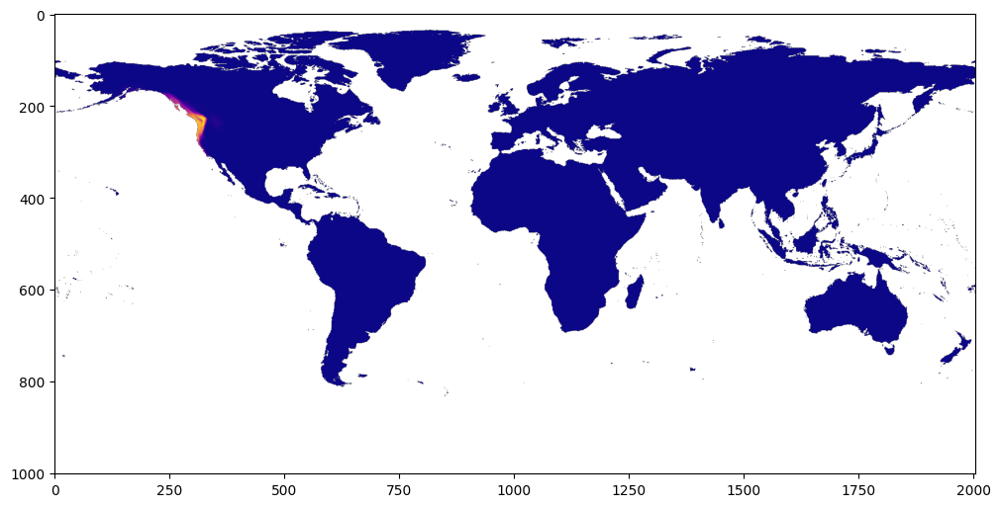

In [459]:
fig, ax1 = plt.subplots(figsize=(12,8))
ax1.imshow(plt.imread(filename), interpolation=None)

# ok let's try with the pydeck style maps

In [460]:
ocean_mask_file = "/home/alex/sinr/data/masks/ocean_mask.npy"
mask = np.load(ocean_mask_file)
mask_inds = np.where(mask.reshape(-1) == 1)[0]
locs = coord_grid(mask.shape) # no ocean mask

In [461]:
dfh3 = pd.DataFrame(locs, columns=["lat", "lng"]).h3.geo_to_h3(resolution=4).reset_index()
dfh3.drop_duplicates(subset=["h3_04"], inplace=True)
_ = dfh3.pop("lat")
_ = dfh3.pop("lng")
dfh3.set_index("h3_04", inplace=True)
dfh3 = dfh3.h3.h3_to_geo()
dfh3["lng"] = dfh3.geometry.x
dfh3["lat"] = dfh3.geometry.y
_ = dfh3.pop("geometry")

In [462]:
len(dfh3)

288122

In [463]:
geo_model_features = gp_model_tf_sinr_coords.features_for_one_class(
    latitude=dfh3["lat"],
    longitude=dfh3["lng"],
)

In [464]:
preds = gp_model_tf_sinr_coords.eval_one_class_from_features(
    geo_model_features, taxon.spatial_class_id
)
len(preds[0])

288122

In [465]:
geo_scores_df

,h3_04,lng,lat,geo_score,scaled_geo_score,hue,sat,val,alpha,red,grn,blu
0,846c59dffffffff,-90.078717,-0.000652,0.000124,0.026397,0.827451,0.422935,0.411879,0.026397,0.405731,0.237681,0.411879
1,846c591ffffffff,-89.840125,-0.357185,0.000113,0.015223,0.827451,0.417459,0.406850,0.015223,0.400856,0.237007,0.406850
2,843cd0dffffffff,90.002875,20.944938,0.000162,0.059835,0.827451,0.439319,0.426926,0.059835,0.420306,0.239369,0.426926
3,843cd47ffffffff,89.793595,21.322353,0.000267,0.121099,0.827451,0.469338,0.454494,0.121099,0.446966,0.241183,0.454494
4,843cd43ffffffff,90.048292,21.684082,0.000331,0.147838,0.827451,0.482441,0.466527,0.147838,0.458583,0.241455,0.466527
...,...,...,...,...,...,...,...,...,...,...,...,...
63958,843c741ffffffff,90.283928,31.590051,0.000238,0.106932,0.827451,0.462397,0.448119,0.106932,0.440806,0.240910,0.448119
63959,843c099ffffffff,90.300615,29.180902,0.000308,0.138666,0.827451,0.477946,0.462400,0.138666,0.454600,0.241397,0.462400
63960,843c095ffffffff,90.253331,28.491682,0.000470,0.190938,0.827451,0.503560,0.485922,0.190938,0.477286,0.241231,0.485922
63961,843ce29ffffffff,90.278860,25.318159,0.001159,0.302430,0.827451,0.558191,0.536094,0.302430,0.525532,0.236851,0.536094


In [466]:
geo_scores_df = dfh3.copy()

geo_scores_df["geo_score"] = tf.squeeze(preds).numpy()

lower_bound_score = 0.0001

geo_scores_df = geo_scores_df[geo_scores_df.geo_score>lower_bound_score]
geo_scores_df = geo_scores_df.reset_index()
len(geo_scores_df)

20274

In [467]:
min_score = geo_scores_df.geo_score.min()
max_score = geo_scores_df.geo_score.max()
geo_scores_df["scaled_geo_score"] = (
    np.log10(geo_scores_df["geo_score"]) - math.log10(min_score)) / (math.log10(max_score) - math.log10(min_score)
)

def map_range(value, old_min, old_max, new_min, new_max):
    return (value - old_min) / (old_max - old_min) * (new_max - new_min) + new_min


In [468]:
geo_scores_df

,h3_04,lng,lat,geo_score,scaled_geo_score
0,843cd05ffffffff,90.211788,20.566019,0.000170,0.058499
1,843cd0dffffffff,90.002875,20.944938,0.000250,0.101406
2,843cd47ffffffff,89.793595,21.322353,0.000259,0.105010
3,843cd43ffffffff,90.048292,21.684082,0.000288,0.116899
4,843cd4bffffffff,89.838523,22.059328,0.000273,0.110876
...,...,...,...,...,...
20269,8426401ffffffff,-89.737557,38.313667,0.000198,0.075668
20270,8426447ffffffff,-89.732742,39.016509,0.000287,0.116599
20271,842644dffffffff,-89.727859,39.715249,0.000239,0.096297
20272,843ce29ffffffff,90.278860,25.318159,0.000536,0.185577


In [469]:
geo_scores_df["hue"] = 211.0 / 255.0
geo_scores_df["sat"] = geo_scores_df["scaled_geo_score"].map(
    lambda x: map_range(x, 0.0, 1.0, 0.41, 0.9)
)
geo_scores_df["val"] = geo_scores_df["scaled_geo_score"].map(
    lambda x: map_range(x, 0.0, 1.0, 0.4, 0.85)
)
geo_scores_df["alpha"] = geo_scores_df["scaled_geo_score"]

geo_scores_df["red"] = geo_scores_df.apply(lambda x: colorsys.hsv_to_rgb(
    x["hue"], x["sat"], x["val"]
)[0], axis=1)
geo_scores_df["grn"] = geo_scores_df.apply(lambda x: colorsys.hsv_to_rgb(
    x["hue"], x["sat"], x["val"]
)[1], axis=1)
geo_scores_df["blu"] = geo_scores_df.apply(lambda x: colorsys.hsv_to_rgb(
    x["hue"], x["sat"], x["val"]
)[2], axis=1)

In [470]:
view_state_grid = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-122.4194155, 
    zoom=3, 
    bearing=0, 
    pitch=0
)
layer_grid = pdk.Layer(
    "H3HexagonLayer",
    geo_scores_df,
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[red * 255 * 0.3, grn * 255, blu * 255, alpha * 255]",
    get_line_color=[255, 100, 100],
    line_width_min_pixels=0,
)
r_grid = pdk.Deck(
    layers=[layer_grid], 
    initial_view_state=view_state_grid,
    map_style=pdk.map_styles.LIGHT,
)
r_grid.show()